# Módulo 4 - Evaluación crítica del modelo SOLARIS
## Validación, interpretabilidad, sesgos, riesgos e impacto ético

**Proyecto:** SOLARIS - FrescaMar S.A.S.  

Este notebook está diseñado para ejecutarse **de inicio a fin desde la raíz del repositorio o desde `Modulo_4/`**. Todas las rutas son relativas al proyecto y los artefactos se escriben en `Modulo_4/tables/` y `Modulo_4/figures/`.

La clase positiva es **Moroso = 1** y la clase negativa **Al día = 0**. Los registros `Cancelado` se excluyen del problema binario.

## 0. Configuración y reproducibilidad

El flujo conserva la misma definición del proyecto: split estratificado 80/20 con `random_state=42`. El conjunto de **prueba no se utiliza para reentrenar el modelo final**; se emplea exclusivamente para evaluación y auditoría. Las comparaciones de umbral que se muestran más adelante son análisis de sensibilidad y **no deben usarse para escoger el umbral definitivo sobre test**.

In [1]:
from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    precision_recall_curve
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Detectar raíz del repositorio
cwd = Path.cwd().resolve()
if (cwd / "src").exists() and (cwd / "data").exists():
    PROJECT_ROOT = cwd
elif cwd.name in {"notebooks", "Modulo_4"}:
    PROJECT_ROOT = cwd.parent
else:
    candidates = [cwd] + list(cwd.parents)
    PROJECT_ROOT = next((p for p in candidates if (p / "src").exists() and (p / "data").exists()), cwd)

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "solaris_datos_limpios.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "artifacts" / "solaris_rf_v1_20260916.joblib"
MODULO4_PATH = PROJECT_ROOT / "Modulo_4"
TABLES_PATH = MODULO4_PATH / "tables"
FIGURES_PATH = MODULO4_PATH / "figures"
TABLES_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

assert DATA_PATH.exists(), f"No se encontró {DATA_PATH}"
assert MODEL_PATH.exists(), f"No se encontró {MODEL_PATH}"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_PATH:", DATA_PATH)
print("MODEL_PATH:", MODEL_PATH)

PROJECT_ROOT: C:\Users\anaso\Downloads\proyecto-solaris
DATA_PATH: C:\Users\anaso\Downloads\proyecto-solaris\data\processed\solaris_datos_limpios.csv
MODEL_PATH: C:\Users\anaso\Downloads\proyecto-solaris\models\artifacts\solaris_rf_v1_20260916.joblib


## 1. Datos, población de modelado y conjunto de prueba



In [2]:
df = pd.read_csv(DATA_PATH)

df_modelo = df[df["estado_cuenta"].isin(["Al día", "Moroso"])].copy()
df_modelo["mora"] = df_modelo["estado_cuenta"].map({"Al día": 0, "Moroso": 1})

features = [
    "edad", "ingreso_mensual", "saldo_actual", "cuotas_pagadas",
    "cuotas_totales", "score_externo", "nivel_educativo", "ciudad"
]

X = df_modelo[features].copy()
y = df_modelo["mora"].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE,
    stratify=y, shuffle=True
)

modelo = joblib.load(MODEL_PATH)

print("Población modelada:", len(df_modelo))
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Prevalencia mora train:", round(y_train.mean(), 4))
print("Prevalencia mora test :", round(y_test.mean(), 4))

Población modelada: 12300
Train: (9840, 8) Test: (2460, 8)
Prevalencia mora train: 0.1463
Prevalencia mora test : 0.1463


## 2. Validación técnica robusta
### 2.1 Métricas honestas en train y test

El ROC-AUC de entrenamiento se usa únicamente para medir la **brecha de generalización**. Las métricas de desempeño operacional se reportan sobre test.

In [3]:
def metricas_binarias(model, X_, y_):
    pred = model.predict(X_)
    prob = model.predict_proba(X_)[:, 1]
    return {
        "accuracy": accuracy_score(y_, pred),
        "precision_moroso": precision_score(y_, pred, zero_division=0),
        "recall_moroso": recall_score(y_, pred, zero_division=0),
        "f1_moroso": f1_score(y_, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_, prob),
    }

m_train = metricas_binarias(modelo, X_train, y_train)
m_test = metricas_binarias(modelo, X_test, y_test)

resumen_metricas = pd.DataFrame([
    {"conjunto": "Train", **m_train},
    {"conjunto": "Test", **m_test},
])
resumen_metricas["brecha_auc_vs_test"] = resumen_metricas["roc_auc"] - m_test["roc_auc"]

display(resumen_metricas.round(4))
resumen_metricas.to_csv(TABLES_PATH / "metricas_train_test.csv", index=False)

print("Brecha ROC-AUC train-test:", round(m_train["roc_auc"] - m_test["roc_auc"], 4))

,conjunto,accuracy,precision_moroso,recall_moroso,f1_moroso,roc_auc,brecha_auc_vs_test
0,Train,0.9684,0.9845,0.7965,0.8806,0.9980,0.0391
1,Test,0.9362,0.9076,0.6278,0.7422,0.9588,0.0000


Brecha ROC-AUC train-test: 0.0391


**Lectura esperada con el artefacto actual:** ROC-AUC Test ≈ **0.9588**, Accuracy ≈ **0.9362**, Precision Moroso ≈ **0.9076**, Recall Moroso ≈ **0.6278** y F1 ≈ **0.7422**. El principal límite operacional es el recall: el modelo identifica cerca del 62.8% de los morosos reales, por debajo del objetivo de negocio de 75%.

### 2.2 Matriz de confusión y lectura de negocio

,Pred. Al día,Pred. Moroso
Real Al día,2077,23
Real Moroso,134,226


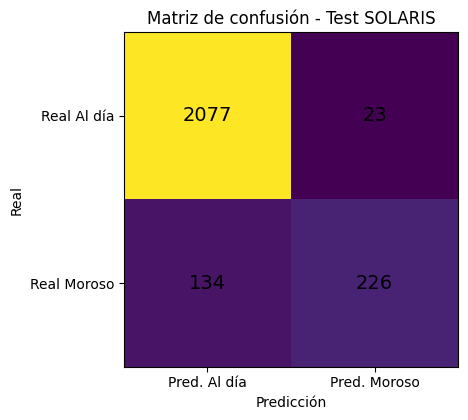

Falsos negativos: 134 de 360 morosos reales (37.2%).
Falsos positivos: 23 de 2100 clientes al día (1.1%).


In [4]:
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0,1]).ravel()
cm = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Real Al día", "Real Moroso"],
    columns=["Pred. Al día", "Pred. Moroso"]
)
display(cm)
cm.to_csv(TABLES_PATH / "matriz_confusion_test.csv")

fig, ax = plt.subplots(figsize=(5.5,4.3))
im = ax.imshow(cm.values)
for i in range(2):
    for j in range(2):
        ax.text(j, i, int(cm.values[i,j]), ha="center", va="center", fontsize=14)
ax.set_xticks([0,1], cm.columns)
ax.set_yticks([0,1], cm.index)
ax.set_title("Matriz de confusión - Test SOLARIS")
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
fig.tight_layout()
fig.savefig(FIGURES_PATH / "confusion_matrix_modulo4.png", dpi=180, bbox_inches="tight")
plt.show()

print(f"Falsos negativos: {fn} de {fn+tp} morosos reales ({fn/(fn+tp):.1%}).")
print(f"Falsos positivos: {fp} de {tn+fp} clientes al día ({fp/(tn+fp):.1%}).")

**Lectura de negocio.** Un falso negativo es un distribuidor realmente moroso clasificado como `Al día`; puede recibir un seguimiento insuficiente y aumentar la exposición de cartera. Un falso positivo es un distribuidor al día clasificado como `Moroso`; puede ser sometido a controles innecesarios, fricción comercial o revisión adicional. En SOLARIS el error prioritario es el falso negativo porque el recall de mora está por debajo del objetivo de 75%.

### 2.3 Evidencia de generalización: validación cruzada

Se evalúa el pipeline final mediante validación cruzada estratificada de 5 folds sobre **train**. El test permanece fuera de este proceso.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(
    clone(modelo), X_train, y_train,
    scoring="roc_auc", cv=cv, n_jobs=-1
)

df_cv = pd.DataFrame({"fold": np.arange(1,6), "roc_auc": cv_auc})
display(df_cv.round(4))
print("ROC-AUC CV media:", round(cv_auc.mean(),4))
print("ROC-AUC CV desviación:", round(cv_auc.std(ddof=1),4))
df_cv.to_csv(TABLES_PATH / "validacion_cruzada_rf.csv", index=False)

,fold,roc_auc
0,1,0.9672
1,2,0.9629
2,3,0.9603
3,4,0.9501
4,5,0.9670


ROC-AUC CV media: 0.9615
ROC-AUC CV desviación: 0.007


### 2.4 Comparación contra baseline simple

La Regresión Logística usa el mismo preprocesamiento del pipeline y sirve como línea base interpretable. El objetivo es demostrar que la complejidad adicional del Random Forest aporta valor fuera del entrenamiento.

In [6]:
preprocessor_base = clone(modelo.named_steps["preprocessor"])
baseline = Pipeline([
    ("preprocessor", preprocessor_base),
    ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])
baseline.fit(X_train, y_train)

base_test = metricas_binarias(baseline, X_test, y_test)
base_cv = cross_val_score(
    baseline, X_train, y_train,
    scoring="roc_auc", cv=cv, n_jobs=-1
)

comparacion = pd.DataFrame([
    {
        "modelo": "Regresión Logística (baseline)",
        "roc_auc_cv_media": base_cv.mean(),
        "roc_auc_test": base_test["roc_auc"],
        "precision_moroso_test": base_test["precision_moroso"],
        "recall_moroso_test": base_test["recall_moroso"],
        "f1_moroso_test": base_test["f1_moroso"],
    },
    {
        "modelo": "Random Forest SOLARIS",
        "roc_auc_cv_media": cv_auc.mean(),
        "roc_auc_test": m_test["roc_auc"],
        "precision_moroso_test": m_test["precision_moroso"],
        "recall_moroso_test": m_test["recall_moroso"],
        "f1_moroso_test": m_test["f1_moroso"],
    }
])
display(comparacion.round(4))
comparacion.to_csv(TABLES_PATH / "comparacion_baseline.csv", index=False)

,modelo,roc_auc_cv_media,roc_auc_test,precision_moroso_test,recall_moroso_test,f1_moroso_test
0,Regresión Logística (baseline),0.9225,0.9241,0.8230,0.5167,0.6348
1,Random Forest SOLARIS,0.9615,0.9588,0.9076,0.6278,0.7422


### 2.5 Sensibilidad del umbral (diagnóstico, no selección sobre test)

Se muestra qué umbrales permitirían alcanzar un recall cercano o superior al objetivo de 75%. **No se selecciona aquí el umbral final**, porque elegirlo directamente con test contaminaría la evaluación. La decisión definitiva debe calibrarse en validación interna o mediante CV y luego confirmarse en un test temporal independiente.

In [7]:
prec, rec, thr = precision_recall_curve(y_test, y_prob)
rows=[]
for t in [0.50,0.45,0.40,0.35,0.30,0.25]:
    yp=(y_prob>=t).astype(int)
    rows.append({
        "threshold": t,
        "precision": precision_score(y_test,yp,zero_division=0),
        "recall": recall_score(y_test,yp,zero_division=0),
        "f1": f1_score(y_test,yp,zero_division=0),
    })
df_umbral=pd.DataFrame(rows)
display(df_umbral.round(4))
df_umbral.to_csv(TABLES_PATH / "sensibilidad_umbral_test_diagnostica.csv", index=False)

,threshold,precision,recall,f1
0,0.50,0.9076,0.6278,0.7422
1,0.45,0.8773,0.6750,0.7630
2,0.40,0.8404,0.7167,0.7736
3,0.35,0.8140,0.7417,0.7762
4,0.30,0.7678,0.7806,0.7741
5,0.25,0.7087,0.8111,0.7565


## 3. Interpretabilidad con SHAP

Se utiliza TreeSHAP sobre el `RandomForestClassifier` del pipeline. El objetivo es explicar tanto el comportamiento global como una decisión individual.

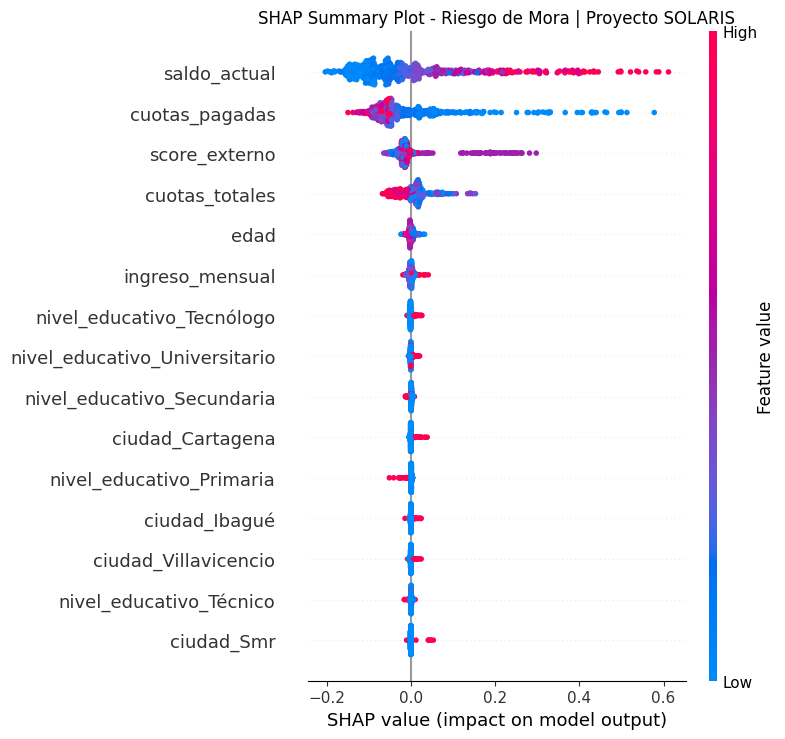

In [8]:
import shap

preprocessor = modelo.named_steps["preprocessor"]
rf = modelo.named_steps["classifier"]
X_test_t = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
if hasattr(X_test_t, "toarray"):
    X_test_t = X_test_t.toarray()
X_test_shap = pd.DataFrame(X_test_t, columns=feature_names)

# Muestra reproducible para explicación global
n_shap = min(600, len(X_test_shap))
X_shap_sample = X_test_shap.sample(n=n_shap, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(rf)
sv_raw = np.asarray(explainer.shap_values(X_shap_sample))

# Compatibilidad entre versiones de SHAP
if sv_raw.ndim == 3:
    shap_values = sv_raw[:, :, 1]
elif isinstance(explainer.shap_values(X_shap_sample), list):
    shap_values = np.asarray(explainer.shap_values(X_shap_sample)[1])
else:
    shap_values = sv_raw

X_plot = X_shap_sample.copy()
X_plot.columns = [c.replace("num__","").replace("cat__","") for c in X_plot.columns]

plt.figure()
shap.summary_plot(shap_values, X_plot, plot_type="dot", max_display=15, show=False)
plt.title("SHAP Summary Plot - Riesgo de Mora | Proyecto SOLARIS")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "shap_summary_plot.png", dpi=180, bbox_inches="tight")
plt.show()

### Interpretación global en lenguaje de negocio

Los factores más influyentes son `saldo_actual`, `cuotas_pagadas` y `score_externo`. Los saldos pendientes altos empujan la predicción hacia mora. En cambio, un mayor número de cuotas pagadas tiende a reducir el riesgo estimado. `score_externo` es el tercer factor más influyente y requiere trazabilidad sobre su origen porque podría incorporar información no visible para el equipo. Las variables de edad, ingreso, educación y ciudad tienen menor peso global, aunque esto no elimina la necesidad de auditar disparidades entre subgrupos.

### 3.2 Caso local: distribuidor con mayor probabilidad de mora

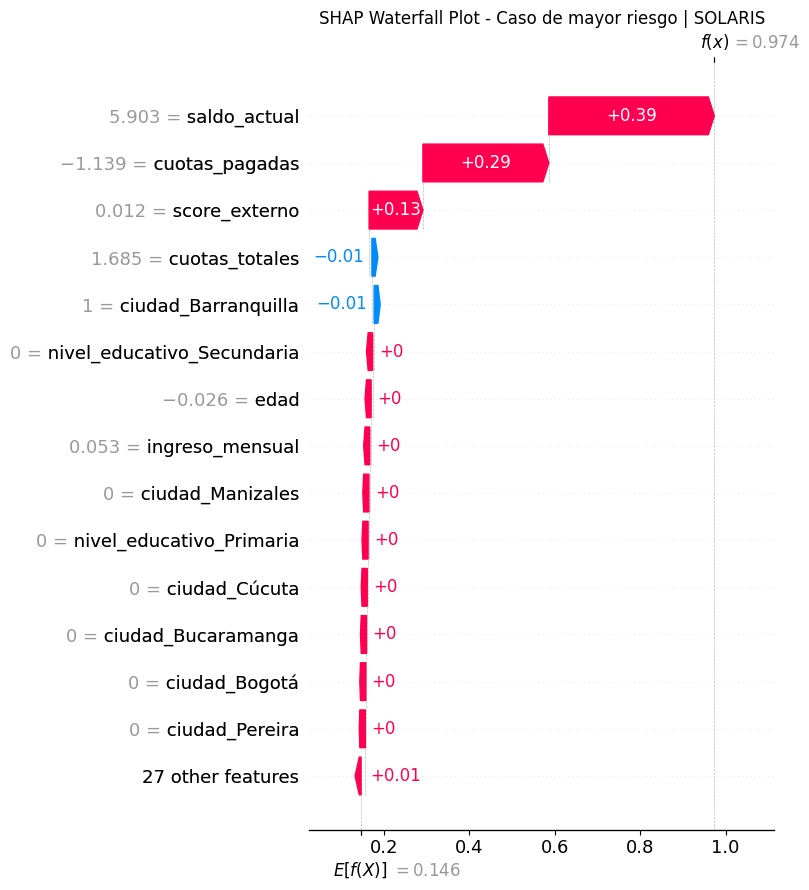

Probabilidad de mora: 0.9737


,valor
edad,48.0
ingreso_mensual,2224968
saldo_actual,27856913
cuotas_pagadas,0
cuotas_totales,48
score_externo,NaN
nivel_educativo,Universitario
ciudad,Barranquilla


In [9]:
idx = int(np.argmax(y_prob))
X_case = X_test.iloc[[idx]]
prob_case = float(y_prob[idx])
X_case_t = preprocessor.transform(X_case)
if hasattr(X_case_t, "toarray"):
    X_case_t = X_case_t.toarray()
X_case_t = np.asarray(X_case_t)

raw_case = np.asarray(explainer.shap_values(X_case_t))
if raw_case.ndim == 3:
    sv_case = raw_case[0,:,1]
else:
    tmp = explainer.shap_values(X_case_t)
    sv_case = np.asarray(tmp[1][0] if isinstance(tmp,list) else tmp[0])

expected = np.asarray(explainer.expected_value)
base = float(expected[1] if expected.ndim else expected)

explanation = shap.Explanation(
    values=sv_case,
    base_values=base,
    data=X_case_t[0],
    feature_names=[c.replace("num__","").replace("cat__","") for c in feature_names]
)

shap.plots.waterfall(explanation, max_display=15, show=False)
plt.title("SHAP Waterfall Plot - Caso de mayor riesgo | SOLARIS")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "shap_waterfall_plot.png", dpi=180, bbox_inches="tight")
plt.show()

print("Probabilidad de mora:", round(prob_case,4))
display(X_case.T.rename(columns={X_case.index[0]:"valor"}))

**Lectura del caso.** En la ejecución de referencia, el caso de mayor riesgo alcanza aproximadamente **97.37%** de probabilidad de mora. Un saldo actual cercano a **$27.9 millones**, **0 cuotas pagadas** y la contribución del `score_externo` son los factores que más elevan la predicción. Esta explicación permite justificar la alerta ante un analista y evita utilizar el score como una caja negra.

## 4. Sesgos y equidad
### 4.1 Preparación de subgrupos

No existen atributos explícitos como género, raza o etnia en el dataset. Se auditan edad, nivel educativo y ciudad como dimensiones disponibles y potenciales proxies. La ausencia de atributos protegidos limita la capacidad de descartar discriminación respecto de características no observadas.

In [10]:
df_eval = X_test.copy()
df_eval["y_real"] = y_test.values
df_eval["y_pred"] = y_pred
df_eval["y_prob"] = y_prob

df_eval["rango_edad"] = pd.cut(
    df_eval["edad"], bins=[0,29,39,49,59,69,120],
    labels=["≤29","30-39","40-49","50-59","60-69","70+"]
)

mapa_ciudades = {
    "Bog":"Bogotá", "Bta":"Bogotá",
    "Mdl":"Medellín", "Med.":"Medellín",
    "Baq":"Barranquilla", "B/Quilla":"Barranquilla", "Barranqilla":"Barranquilla",
    "Bga":"Bucaramanga", "B/Manga":"Bucaramanga",
    "Cal":"Cali", "Santiago De Cali":"Cali",
    "San José De Cúcuta":"Cúcuta", "Mzl":"Manizales", "Pei":"Pereira",
    "Smr":"Santa Marta", "Sta Marta":"Santa Marta", "Villavo":"Villavicencio"
}
df_eval["ciudad_auditoria"] = df_eval["ciudad"].replace(mapa_ciudades)
variables_sensibles = ["rango_edad","nivel_educativo","ciudad_auditoria"]

### 4.2 Desempeño por subgrupos

In [11]:
sub=[]
for var in variables_sensibles:
    for grupo in df_eval[var].dropna().unique():
        m=df_eval[var].eq(grupo)
        if m.sum()>30:
            yr=df_eval.loc[m,"y_real"]
            yp=df_eval.loc[m,"y_pred"]
            pr=df_eval.loc[m,"y_prob"]
            sub.append({
                "variable_sensible":var, "subgrupo":grupo, "n":int(m.sum()),
                "accuracy":accuracy_score(yr,yp),
                "auc_roc":roc_auc_score(yr,pr) if yr.nunique()==2 else np.nan,
                "f1":f1_score(yr,yp,zero_division=0)
            })
df_subgrupos=pd.DataFrame(sub)
display(df_subgrupos.round(4))
df_subgrupos.to_csv(TABLES_PATH/"reporte_subgrupos.csv",index=False)

,variable_sensible,subgrupo,n,accuracy,auc_roc,f1
0,rango_edad,50-59,384,0.9271,0.9629,0.7500
1,rango_edad,≤29,454,0.9229,0.9569,0.6903
2,rango_edad,30-39,363,0.9532,0.9750,0.8317
3,rango_edad,40-49,334,0.9431,0.9742,0.7912
4,rango_edad,70+,370,0.9486,0.9501,0.7324
5,rango_edad,60-69,377,0.9337,0.9311,0.6914
6,nivel_educativo,Tecnólogo,429,0.9441,0.9650,0.7692
7,nivel_educativo,Secundaria,607,0.9292,0.9529,0.7034
8,nivel_educativo,Técnico,499,0.9439,0.9779,0.7667
9,nivel_educativo,Universitario,592,0.9341,0.9469,0.7547


### 4.3 Demographic Parity

La clase positiva es `Moroso = 1`. Se compara la proporción de predicciones positivas entre grupos. Como regla de revisión del ejercicio se utiliza una diferencia superior a 0.10.

In [12]:
dp=[]
for var in variables_sensibles:
    for grupo in df_eval[var].dropna().unique():
        m=df_eval[var].eq(grupo)
        if m.sum()>30:
            dp.append({"variable_sensible":var,"subgrupo":grupo,"n":int(m.sum()),
                       "tasa_prediccion_positiva":df_eval.loc[m,"y_pred"].mean()})
df_dp=pd.DataFrame(dp)

b=[]
for var in variables_sensibles:
    t=df_dp[df_dp.variable_sensible.eq(var)]
    mx=t.loc[t.tasa_prediccion_positiva.idxmax()]
    mn=t.loc[t.tasa_prediccion_positiva.idxmin()]
    gap=float(mx.tasa_prediccion_positiva-mn.tasa_prediccion_positiva)
    b.append({"variable_sensible":var,"grupo_mayor_tasa":mx.subgrupo,"tasa_max":mx.tasa_prediccion_positiva,
              "grupo_menor_tasa":mn.subgrupo,"tasa_min":mn.tasa_prediccion_positiva,"brecha_dp":gap,
              "evaluacion":"ALERTA" if gap>0.10 else "OK"})
df_brechas_dp=pd.DataFrame(b)
display(df_brechas_dp.round(4))
df_dp.to_csv(TABLES_PATH/"reporte_demographic_parity.csv",index=False)
df_brechas_dp.to_csv(TABLES_PATH/"reporte_brechas_demographic_parity.csv",index=False)

,variable_sensible,grupo_mayor_tasa,tasa_max,grupo_menor_tasa,tasa_min,brecha_dp,evaluacion
0,rango_edad,50-59,0.1224,70+,0.0757,0.0467,OK
1,nivel_educativo,Universitario,0.1098,Posgrado,0.0904,0.0194,OK
2,ciudad_auditoria,Manizales,0.1284,Santa Marta,0.0657,0.0628,OK


### 4.4 Equalized Odds

Se comparan TPR (recall de morosos reales) y FPR entre grupos. Una diferencia alta de TPR implica que el modelo detecta morosos con distinta sensibilidad según el subgrupo.

In [13]:
eo=[]
for var in variables_sensibles:
    for grupo in df_eval[var].dropna().unique():
        m=df_eval[var].eq(grupo)
        if m.sum()>30:
            yr=df_eval.loc[m,"y_real"]
            yp=df_eval.loc[m,"y_pred"]
            tn_,fp_,fn_,tp_=confusion_matrix(yr,yp,labels=[0,1]).ravel()
            eo.append({
                "variable_sensible":var,"subgrupo":grupo,"n":int(m.sum()),
                "tn":tn_,"fp":fp_,"fn":fn_,"tp":tp_,
                "TPR":tp_/(tp_+fn_) if tp_+fn_ else np.nan,
                "FPR":fp_/(fp_+tn_) if fp_+tn_ else np.nan
            })
df_eo=pd.DataFrame(eo)

summary=[]
for var in variables_sensibles:
    t=df_eo[df_eo.variable_sensible.eq(var)]
    tpr_max=t.loc[t.TPR.idxmax()]; tpr_min=t.loc[t.TPR.idxmin()]
    fpr_max=t.loc[t.FPR.idxmax()]; fpr_min=t.loc[t.FPR.idxmin()]
    summary.append({
        "variable_sensible":var,
        "TPR_max":tpr_max.TPR,"grupo_TPR_max":tpr_max.subgrupo,
        "TPR_min":tpr_min.TPR,"grupo_TPR_min":tpr_min.subgrupo,
        "brecha_TPR":tpr_max.TPR-tpr_min.TPR,
        "FPR_max":fpr_max.FPR,"grupo_FPR_max":fpr_max.subgrupo,
        "FPR_min":fpr_min.FPR,"grupo_FPR_min":fpr_min.subgrupo,
        "brecha_FPR":fpr_max.FPR-fpr_min.FPR
    })
df_brechas_eo=pd.DataFrame(summary)
display(df_brechas_eo.round(4))
df_eo.to_csv(TABLES_PATH/"reporte_equalized_odds.csv",index=False)
df_brechas_eo.to_csv(TABLES_PATH/"reporte_brechas_equalized_odds.csv",index=False)

,variable_sensible,TPR_max,grupo_TPR_max,TPR_min,grupo_TPR_min,brecha_TPR,FPR_max,grupo_FPR_max,FPR_min,grupo_FPR_min,brecha_FPR
0,rango_edad,0.7368,30-39,0.5490,60-69,0.1878,0.0157,50-59,0.0061,70+,0.0096
1,nivel_educativo,0.6765,Técnico,0.5517,Posgrado,0.1247,0.0139,Técnico,0.0063,Posgrado,0.0076
2,ciudad_auditoria,0.7333,Medellín,0.4800,Cartagena,0.2533,0.0176,Villavicencio,0.0000,Ibagué,0.0176


Las brechas de AUC por subgrupo permanecen por debajo de 0.05 y Demographic Parity no supera 0.10. Sin embargo, Equalized Odds muestra diferencias de TPR aproximadas de **18.78 p.p. por edad**, **12.48 p.p. por nivel educativo** y **25.33 p.p. por ciudad**. La mayor diferencia está entre Medellín (TPR ≈ 0.7333) y Cartagena (TPR ≈ 0.4800). Esto es una **señal de riesgo**, no una prueba causal de discriminación. Algunos subgrupos tienen pocos morosos reales, por lo que la TPR puede ser inestable y debe monitorearse con más datos.

## 5. Riesgos específicos de SOLARIS y mitigaciones

La tabla se limita a **cuatro riesgos**, como exige el checklist. Se incluyen severidad, probabilidad, impacto cuantificado y acción realizable.

In [14]:
riesgos = [
    {
        "Riesgo":"Recall insuficiente de morosos",
        "Severidad":"ALTA", "Probabilidad":"ALTA",
        "Evidencia":"Recall test≈0.6278 vs objetivo 0.75; 134 FN de 360 morosos reales",
        "Impacto":"Morosos no detectados pueden recibir seguimiento insuficiente y elevar exposición de cartera.",
        "Mitigación":"Optimizar el umbral en validación/CV, evaluar class_weight o resampling y validar el costo FN/FP con Crédito y Cartera.",
        "Responsable":"Científico de Datos + Crédito y Cartera", "Plazo":"Antes de producción"
    },
    {
        "Riesgo":"Brecha geográfica de sensibilidad",
        "Severidad":"ALTA", "Probabilidad":"MEDIA",
        "Evidencia":"Equalized Odds: brecha TPR por ciudad≈0.2533; Medellín≈0.7333 vs Cartagena≈0.4800",
        "Impacto":"La capacidad de detectar mora puede variar por ubicación, generando tratamiento desigual y riesgo operativo.",
        "Mitigación":"Normalizar ciudad, revisar representación, probar reweighting/resampling y exigir brecha TPR≤0.10 o justificación aprobada.",
        "Responsable":"Científico de Datos + Líder Técnica", "Plazo":"2 semanas antes de despliegue"
    },
    {
        "Riesgo":"Opacidad del score_externo / proxy",
        "Severidad":"MEDIA", "Probabilidad":"MEDIA",
        "Evidencia":"3.ª variable SHAP global (≈0.0356) y composición del score no documentada",
        "Impacto":"Puede incorporar proxies socioeconómicos/demográficos no auditados y dificultar explicaciones o impugnaciones.",
        "Mitigación":"Obtener ficha de procedencia, variables fuente y política de actualización; repetir fairness con y sin score_externo.",
        "Responsable":"Data Owner + Líder Técnica", "Plazo":"Antes de aprobación de producción"
    },
    {
        "Riesgo":"Validación temporal limitada",
        "Severidad":"MEDIA", "Probabilidad":"MEDIA",
        "Evidencia":"Ventana reciente=136 registros y split original aleatorio, no out-of-time",
        "Impacto":"La estabilidad frente a cambios futuros puede estar sobreestimada; drift real podría detectarse tarde.",
        "Mitigación":"Registrar fecha_scoring/fecha_evento, crear test out-of-time y monitorear KS/PSI y desempeño mensualmente.",
        "Responsable":"Data Engineering + Científico de Datos", "Plazo":"Primer ciclo de producción / 30 días"
    }
]
df_riesgos=pd.DataFrame(riesgos)
display(df_riesgos)
df_riesgos.to_csv(TABLES_PATH/"reporte_riesgos_final.csv",index=False)

,Riesgo,Severidad,Probabilidad,Evidencia,Impacto,Mitigación,Responsable,Plazo
0,Recall insuficiente de morosos,ALTA,ALTA,Recall test≈0.6278 vs objetivo 0.75; 134 FN de...,Morosos no detectados pueden recibir seguimien...,"Optimizar el umbral en validación/CV, evaluar ...",Científico de Datos + Crédito y Cartera,Antes de producción
1,Brecha geográfica de sensibilidad,ALTA,MEDIA,Equalized Odds: brecha TPR por ciudad≈0.2533; ...,La capacidad de detectar mora puede variar por...,"Normalizar ciudad, revisar representación, pro...",Científico de Datos + Líder Técnica,2 semanas antes de despliegue
2,Opacidad del score_externo / proxy,MEDIA,MEDIA,3.ª variable SHAP global (≈0.0356) y composici...,Puede incorporar proxies socioeconómicos/demog...,"Obtener ficha de procedencia, variables fuente...",Data Owner + Líder Técnica,Antes de aprobación de producción
3,Validación temporal limitada,MEDIA,MEDIA,Ventana reciente=136 registros y split origina...,La estabilidad frente a cambios futuros puede ...,"Registrar fecha_scoring/fecha_evento, crear te...",Data Engineering + Científico de Datos,Primer ciclo de producción / 30 días


## 6. Implicaciones éticas y salvaguardas

SOLARIS afecta una **decisión humana de gestión de riesgo de crédito**: priorizar qué distribuidores requieren seguimiento adicional y qué casos merecen revisión. Por ello, el score no debe transformarse automáticamente en rechazo, restricción o sanción. Existe riesgo de **automation bias** si el analista acepta la predicción sin revisar el contexto; de discriminación indirecta si `ciudad`, `nivel_educativo` o `score_externo` funcionan como proxies; y de afectación a la privacidad si datos obtenidos para riesgo crediticio se reutilizan con otros fines.

Salvaguardas propuestas: (1) revisión humana obligatoria para decisiones adversas; (2) explicación local disponible con SHAP; (3) mecanismo de corrección/impugnación de datos; (4) acceso mínimo y trazabilidad de consultas; (5) monitoreo mensual de performance, drift y fairness; (6) documentación de procedencia de `score_externo`; y (7) prohibición expresa de usar SOLARIS como único fundamento para negar o retirar crédito.

## 7. Recomendación final de despliegue

### **DESPLEGAR CON CONDICIONES - únicamente como sistema de apoyo a la decisión**

El modelo muestra buena capacidad discriminativa (ROC-AUC Test ≈ 0.9588), alta precisión para Moroso (≈0.9076) y una brecha train-test controlada. Sin embargo, **no se recomienda un despliegue autónomo** porque el recall de morosos (≈0.6278) está por debajo del objetivo de 0.75 y Equalized Odds revela una brecha de TPR geográfica de ≈25.33 p.p.

Condiciones mínimas antes de producción: recalibrar el umbral usando validación interna; reducir o justificar las brechas de TPR; documentar `score_externo`; incorporar revisión humana; y establecer monitoreo mensual con plan de escalamiento. Hasta cumplirlas, SOLARIS debe usarse como herramienta de priorización y no como decisor final.